# 2013 — Variational Autoencoders (VAE)

**Papers:** Diederik Kingma & Max Welling, *"Auto-Encoding Variational Bayes"* (2013); Rezende, Mohamed & Wierstra (2014).

A plain autoencoder's code space has holes, so decoding a random code gives garbage. A VAE makes it a proper **generative model** $p_\theta(x) = \int p_\theta(x|z)\,p(z)\,dz$ with prior $p(z) = \mathcal N(0, I)$:

- the encoder outputs a **distribution** $q_\phi(z|x) = \mathcal N(\mu_\phi(x), \sigma^2_\phi(x))$
- training maximises the **ELBO** $\;\mathbb E_{q}[\log p_\theta(x|z)] - \mathrm{KL}(q_\phi(z|x)\,\|\,p(z)) \le \log p_\theta(x)$
- the **reparameterisation trick** $z = \mu + \sigma \odot \epsilon,\ \epsilon\sim\mathcal N(0,I)$ lets gradients flow through sampling.

Then you can **generate** new data by decoding $z \sim \mathcal N(0, I)$.

![Diagram: Variational autoencoder (Kingma & Welling, 2013)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/19_2013_vae.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = load_digits_tensors()
Xtr, Xte = Xtr.flatten(1).to(device), Xte.flatten(1).to(device)

step    0  -ELBO 44.81  (recon 44.80, KL 0.00)


step 1500  -ELBO 23.80  (recon 21.16, KL 2.64)


step 3000  -ELBO 23.64  (recon 20.48, KL 3.16)


step 4500  -ELBO 23.17  (recon 19.74, KL 3.43)


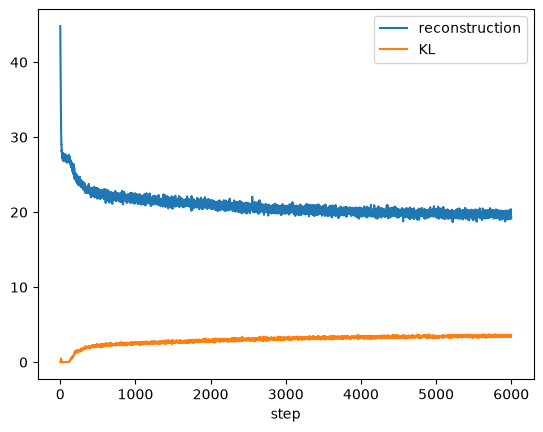

In [3]:
class VAE(nn.Module):
    def __init__(self, d_in=64, h=256, z=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d_in, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU())
        self.mu, self.logvar = nn.Linear(h, z), nn.Linear(h, z)
        self.dec = nn.Sequential(nn.Linear(z, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, d_in))

    def forward(self, x):
        e = self.enc(x)
        mu, logvar = self.mu(e), self.logvar(e)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)        # reparameterisation trick
        return self.dec(z), mu, logvar

def elbo_loss(x, logits, mu, logvar):
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x)   # -E_q[log p(x|z)]
    kl = -0.5 * torch.sum(1 + logvar - mu ** 2 - logvar.exp()) / len(x)          # closed-form Gaussian KL
    return rec + kl, rec, kl

vae = VAE().to(device)
opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
hist = []
for step in range(6000):
    x = Xtr[torch.randint(0, len(Xtr), (128,), device=device)]
    loss, rec, kl = elbo_loss(x, *vae(x))
    opt.zero_grad(); loss.backward(); opt.step()
    hist.append((rec.item(), kl.item()))
    if step % 1500 == 0: print(f"step {step:4d}  -ELBO {loss.item():.2f}  (recon {rec.item():.2f}, KL {kl.item():.2f})")
h = np.array(hist)
plt.plot(h[:, 0], label="reconstruction"); plt.plot(h[:, 1], label="KL"); plt.legend(); plt.xlabel("step"); plt.show()

## The latent space is smooth and close to $\mathcal N(0, I)$

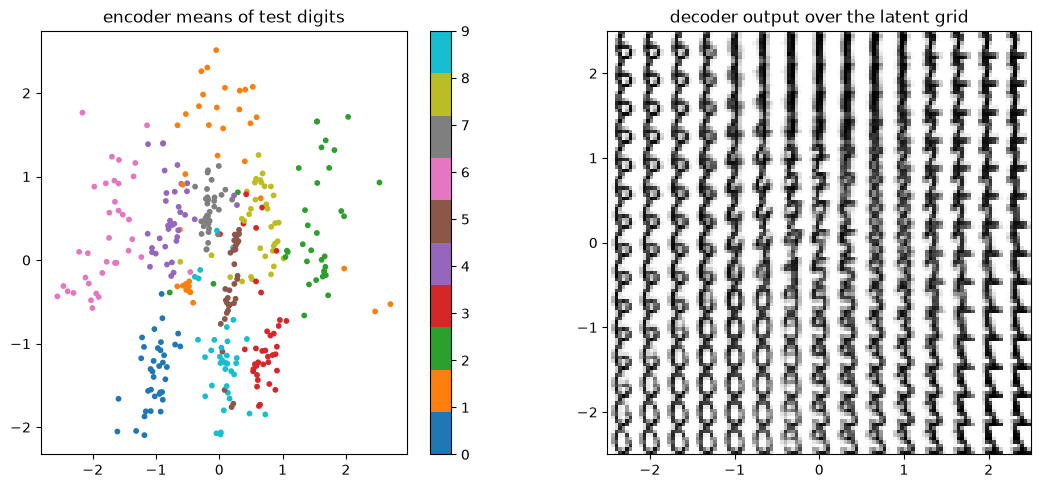

In [4]:
vae.eval()
with torch.no_grad():
    mu = vae.mu(vae.enc(Xte)).cpu()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
sc = axes[0].scatter(mu[:, 0], mu[:, 1], c=yte, cmap="tab10", s=10); fig.colorbar(sc, ax=axes[0], ticks=range(10))
axes[0].set_title("encoder means of test digits")
# decode a grid of latent points
grid = torch.linspace(-2.5, 2.5, 15)
zz = torch.stack(torch.meshgrid(grid, grid.flip(0), indexing="xy"), -1).reshape(-1, 2).to(device)
with torch.no_grad():
    imgs = torch.sigmoid(vae.dec(zz)).cpu().view(15, 15, 8, 8)
canvas = imgs.permute(0, 2, 1, 3).reshape(15 * 8, 15 * 8)
axes[1].imshow(canvas, cmap="gray_r", extent=[-2.5, 2.5, -2.5, 2.5]); axes[1].set_title("decoder output over the latent grid")
plt.show()

## Sampling new digits from the prior

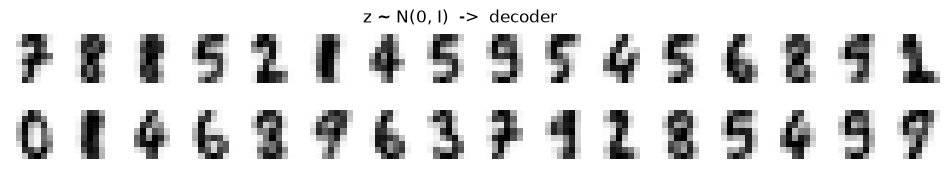

In [5]:
with torch.no_grad():
    samples = torch.sigmoid(vae.dec(torch.randn(32, 2, device=device))).cpu()
fig, axes = plt.subplots(2, 16, figsize=(12, 1.8))
for a, s in zip(axes.flat, samples): a.imshow(s.view(8, 8), cmap="gray_r"); a.axis("off")
plt.suptitle("z ~ N(0, I)  ->  decoder"); plt.show()